# Análise de cancelamento de clientes

**Case:** uma empresa de assinaturas percebeu que a maioria da sua base é de clientes que já cancelaram. A pergunta é: **quais são os principais motivos do cancelamento e quais ações teriam mais efeito para reduzi-lo?**

Projeto baseado na *Aula 2 da Jornada Python* (Hashtag Treinamentos), com correções e uma segunda etapa de verificação com **árvore de decisão (scikit-learn)**.

> ⚠️ **A base é fictícia (de curso).** Os padrões são limpos demais: vários grupos cancelam exatamente 100%. Em dados reais isso não acontece, então os números servem para praticar o método, não para tirar conclusões sobre uma empresa real.

**Roteiro**

1. Importar e limpar a base
2. Taxa geral de cancelamento
3. Quais variáveis se relacionam com o cancelamento?
4. Pontos de virada (a partir de onde todos cancelam)
5. Funil: quantos clientes sobram depois de cada ação
6. Cenários: quanto cada ação reduziria o cancelamento
7. Cuidados com as conclusões
8. Árvore de decisão (scikit-learn) para conferir os cortes
9. Conclusões

## 1. Importar e limpar a base

Antes de apagar a coluna `CustomerID`, é preciso **conferir se há clientes repetidos**: depois que o ID some, não dá mais para saber quem é duplicado. Na versão da aula o ID era apagado logo no início e o problema passava despercebido.

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

os.makedirs('imagens', exist_ok=True)

AZUL = '#2a6fb0'      # cor principal dos gráficos
VERMELHO = '#b3402a'  # destaque: grupos em que (quase) todos cancelam
CINZA = '#8b95a1'     # linhas de referência

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold'})

def pct(x, casas=1):
    """0.567 -> '56,7%' (formato brasileiro)."""
    return f'{x * 100:.{casas}f}%'.replace('.', ',')

def milhar(n):
    """48527 -> '48.527'."""
    return f'{n:,.0f}'.replace(',', '.')

In [20]:
base_original = pd.read_csv('cancelamentos.csv')
print('Linhas e colunas:', base_original.shape)
display(base_original.head())
base_original.info()

Linhas e colunas: (50000, 12)


,CustomerID,idade,sexo,tempo_como_cliente,frequencia_uso,ligacoes_callcenter,dias_atraso,assinatura,duracao_contrato,total_gasto,meses_ultima_interacao,cancelou
0,349936.0,23.0,Male,13.0,22.0,2.0,1.0,Standard,Annual,909.58,23.0,0.0
1,100634.0,49.0,Male,55.0,16.0,3.0,6.0,Premium,Monthly,207.00,29.0,1.0
2,301263.0,30.0,Male,7.0,1.0,0.0,8.0,Basic,Annual,768.78,7.0,0.0
3,119358.0,26.0,Male,40.0,5.0,3.0,8.0,Premium,Annual,398.00,12.0,1.0
4,130955.0,27.0,Female,17.0,30.0,5.0,6.0,Basic,Annual,507.00,15.0,1.0


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              50000 non-null  float64
 1   idade                   50000 non-null  float64
 2   sexo                    49997 non-null  str    
 3   tempo_como_cliente      49998 non-null  float64
 4   frequencia_uso          50000 non-null  float64
 5   ligacoes_callcenter     50000 non-null  float64
 6   dias_atraso             50000 non-null  float64
 7   assinatura              50000 non-null  str    
 8   duracao_contrato        50000 non-null  str    
 9   total_gasto             50000 non-null  float64
 10  meses_ultima_interacao  50000 non-null  float64
 11  cancelou                50000 non-null  float64
dtypes: float64(9), str(3)
memory usage: 5.5 MB


In [21]:
# Duplicados: conferir ANTES de apagar o CustomerID
ids_repetidos = base_original['CustomerID'].duplicated().sum()
linhas_identicas = base_original.duplicated().sum()
print('IDs repetidos:', ids_repetidos)
print('Linhas 100% idênticas:', linhas_identicas)

IDs repetidos: 1469
Linhas 100% idênticas: 1469


Todos os IDs repetidos são **cópias exatas** (a linha inteira é igual), então podem ser removidos sem perder informação. Depois disso o `CustomerID` pode sair, pois é só um identificador e não explica o cancelamento.

In [22]:
base = base_original.drop_duplicates().drop(columns='CustomerID')

# Valores vazios por coluna
vazios = base.isna().sum()
display(vazios[vazios > 0])

# Como são poucas linhas, apagá-las é seguro
tabela_limpa = base.dropna().copy()

# Colunas que são números inteiros vieram como decimais (23.0). Ajustando:
colunas_inteiras = ['idade', 'tempo_como_cliente', 'frequencia_uso', 'ligacoes_callcenter',
                    'dias_atraso', 'meses_ultima_interacao', 'cancelou']
tabela_limpa[colunas_inteiras] = tabela_limpa[colunas_inteiras].astype(int)

print('Linhas antes:', milhar(len(base_original)), '| depois da limpeza:', milhar(len(tabela_limpa)))
display(tabela_limpa.head())

sexo                  3
tempo_como_cliente    2
dtype: int64

Linhas antes: 50.000 | depois da limpeza: 48.527


,idade,sexo,tempo_como_cliente,frequencia_uso,ligacoes_callcenter,dias_atraso,assinatura,duracao_contrato,total_gasto,meses_ultima_interacao,cancelou
0,23,Male,13,22,2,1,Standard,Annual,909.58,23,0
1,49,Male,55,16,3,6,Premium,Monthly,207.00,29,1
2,30,Male,7,1,0,8,Basic,Annual,768.78,7,0
3,26,Male,40,5,3,8,Premium,Annual,398.00,12,1
4,27,Female,17,30,5,6,Basic,Annual,507.00,15,1


## 2. Taxa geral de cancelamento

A coluna `cancelou` vale 1 para quem cancelou e 0 para quem ficou. Por isso, **a média da coluna é a taxa de cancelamento**. Essa ideia vai ser usada o tempo todo.

In [23]:
taxa_geral = tabela_limpa['cancelou'].mean()
print('Clientes na base limpa:', milhar(len(tabela_limpa)))
print('Cancelaram:', milhar(tabela_limpa['cancelou'].sum()), '->', pct(taxa_geral))
display(tabela_limpa['cancelou'].value_counts().rename({0: 'Ficaram', 1: 'Cancelaram'}))

Clientes na base limpa: 48.527
Cancelaram: 27.539 -> 56,7%


cancelou
Cancelaram    27539
Ficaram       20988
Name: count, dtype: int64

## 3. Quais variáveis se relacionam com o cancelamento?

Na versão da aula, o gráfico de cada coluna era um histograma com contagens (o `plotly` abre uma janela por coluna, e as contagens dificultam a comparação). Aqui cada gráfico mostra **a taxa de cancelamento por grupo**, com a taxa geral como linha de referência. Barras **vermelhas** são grupos onde praticamente todos cancelam (≥ 99%).

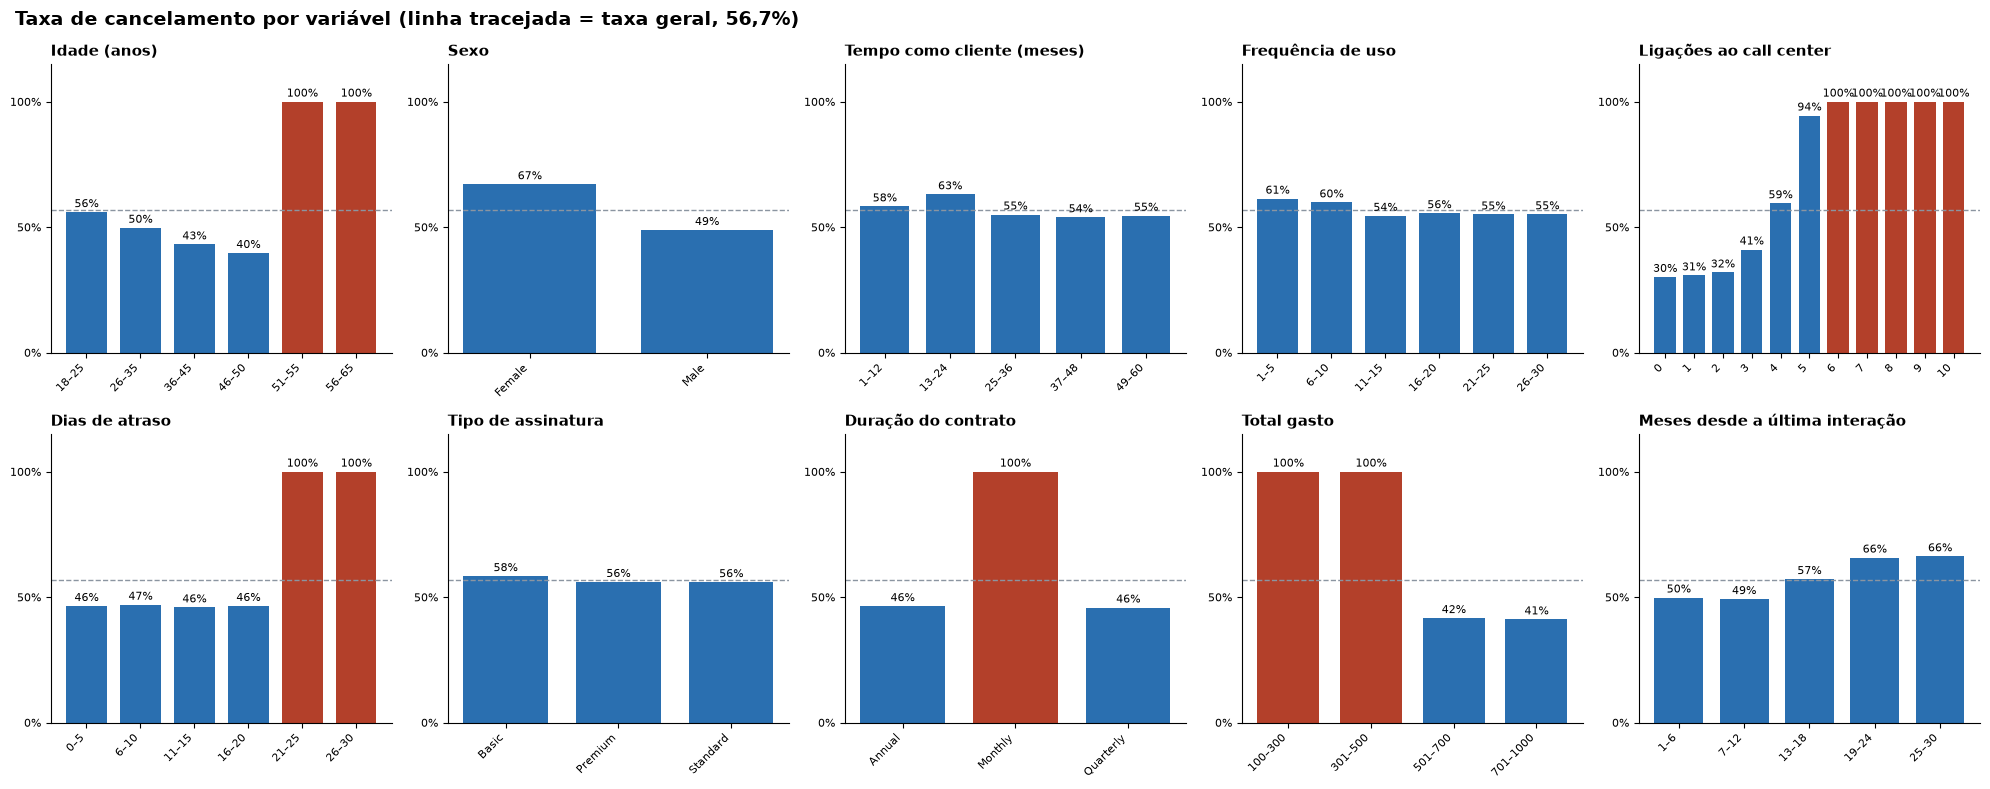

In [24]:
def taxa_por_grupo(coluna, cortes=None):
    """Taxa de cancelamento por valor (ou por faixa, se 'cortes' for informado)."""
    serie = tabela_limpa[coluna]
    if cortes:
        rotulos = [f'{a + 1}–{b}' for a, b in zip(cortes[:-1], cortes[1:])]
        serie = pd.cut(serie, bins=cortes, labels=rotulos)
    return tabela_limpa.groupby(serie, observed=True)['cancelou'].mean()

def desenhar_taxa(ax, taxa, titulo):
    cores = [VERMELHO if v >= 0.99 else AZUL for v in taxa.values]
    posicoes = range(len(taxa))
    ax.bar(posicoes, taxa.values, color=cores, width=0.75)
    ax.axhline(taxa_geral, color=CINZA, linestyle='--', linewidth=1)
    for i, v in zip(posicoes, taxa.values):
        ax.text(i, v + 0.02, f'{v * 100:.0f}%', ha='center', fontsize=8)
    ax.set_xticks(list(posicoes))
    ax.set_xticklabels([str(x) for x in taxa.index], fontsize=8, rotation=45, ha='right')
    ax.set_ylim(0, 1.15)
    ax.set_yticks([0, 0.5, 1])
    ax.set_yticklabels(['0%', '50%', '100%'], fontsize=8)
    ax.set_title(titulo, loc='left')

variaveis = [
    ('idade', 'Idade (anos)', [17, 25, 35, 45, 50, 55, 65]),
    ('sexo', 'Sexo', None),
    ('tempo_como_cliente', 'Tempo como cliente (meses)', [0, 12, 24, 36, 48, 60]),
    ('frequencia_uso', 'Frequência de uso', [0, 5, 10, 15, 20, 25, 30]),
    ('ligacoes_callcenter', 'Ligações ao call center', None),
    ('dias_atraso', 'Dias de atraso', [-1, 5, 10, 15, 20, 25, 30]),
    ('assinatura', 'Tipo de assinatura', None),
    ('duracao_contrato', 'Duração do contrato', None),
    ('total_gasto', 'Total gasto', [99, 300, 500, 700, 1000]),
    ('meses_ultima_interacao', 'Meses desde a última interação', [0, 6, 12, 18, 24, 30]),
]

fig, eixos = plt.subplots(2, 5, figsize=(20, 8))
for ax, (coluna, titulo, cortes) in zip(eixos.flat, variaveis):
    desenhar_taxa(ax, taxa_por_grupo(coluna, cortes), titulo)
fig.suptitle(f'Taxa de cancelamento por variável (linha tracejada = taxa geral, {pct(taxa_geral)})',
             fontsize=14, fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
fig.savefig('imagens/painel_taxa_por_variavel.png', dpi=110, bbox_inches='tight')
plt.show()

**O que o painel mostra** (observação, não prova de causa):

- **Contrato mensal**: o grupo inteiro cancela.
- **Ligações ao call center**: a taxa sobe com o número de ligações e chega a 100% a partir de 6.
- **Dias de atraso**: acima de 20 dias, todos cancelam.
- **Idade** (acima de 50) e **total gasto** (até 500): também aparecem com 100%. A aula não tratou esses dois.
- **Meses desde a última interação**: a taxa sobe de cerca de 50% (até 12 meses) para cerca de 66% (mais de 18 meses).
- **Sexo**: há diferença visível (mulheres 67%, homens 49%). Isso pede cuidado, comentado na seção 7.
- **Tipo de assinatura, tempo como cliente e frequência de uso** ficam próximos da taxa geral (entre 54% e 63%).

## 4. Pontos de virada

Os cortes da aula foram escolhidos "no olho" (4 ligações, 20 dias). Aqui cada corte é conferido nos dados: a partir de que valor a taxa chega a 100%?

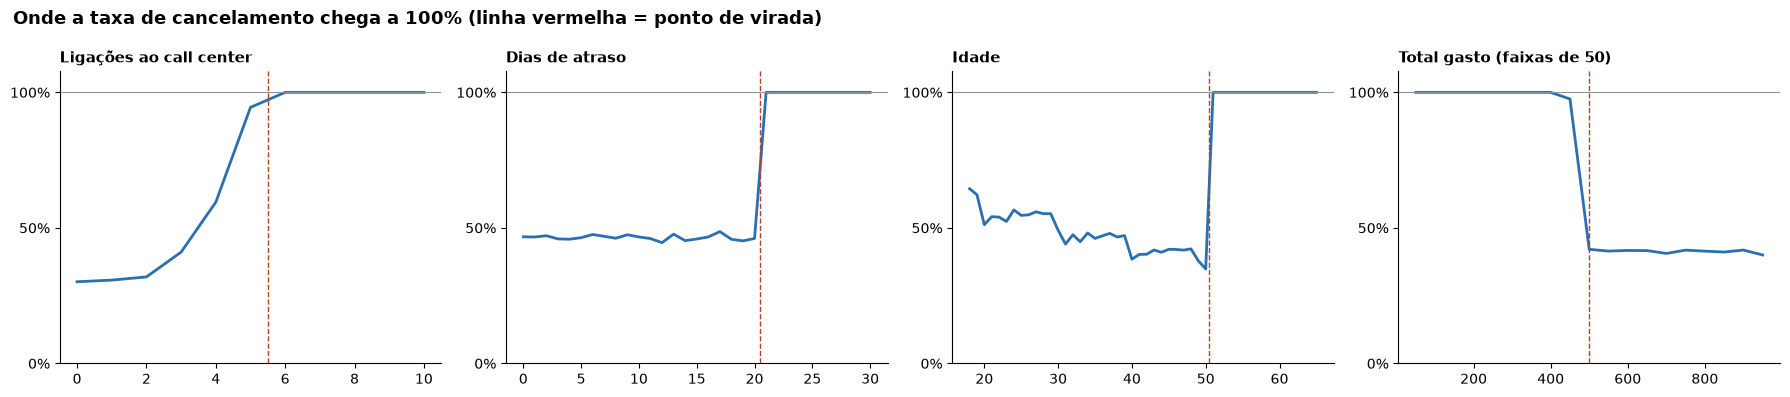

In [25]:
def curva_por_valor(coluna, passo=1):
    # faixas (1-50], (50-100]...: o valor 1000 entra na última faixa, não numa faixa sozinho
    base_x = ((tabela_limpa[coluna] - 1) // passo) * passo if passo > 1 else tabela_limpa[coluna]
    return tabela_limpa.groupby(base_x)['cancelou'].mean()

fig, eixos = plt.subplots(1, 4, figsize=(18, 4))
curvas = [
    ('ligacoes_callcenter', 1, 'Ligações ao call center', 5.5),
    ('dias_atraso', 1, 'Dias de atraso', 20.5),
    ('idade', 1, 'Idade', 50.5),
    ('total_gasto', 50, 'Total gasto (faixas de 50)', 500),
]
for ax, (coluna, passo, titulo, corte) in zip(eixos, curvas):
    c = curva_por_valor(coluna, passo)
    ax.plot(c.index, c.values, color=AZUL, linewidth=2)
    ax.axvline(corte, color=VERMELHO, linestyle='--', linewidth=1)
    ax.axhline(1, color=CINZA, linewidth=0.8)
    ax.set_ylim(0, 1.08)
    ax.set_yticks([0, 0.5, 1]); ax.set_yticklabels(['0%', '50%', '100%'])
    ax.set_title(titulo, loc='left')
fig.suptitle('Onde a taxa de cancelamento chega a 100% (linha vermelha = ponto de virada)',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
fig.savefig('imagens/pontos_de_virada.png', dpi=110, bbox_inches='tight')
plt.show()

In [26]:
# Tabela de regras: tamanho do grupo e taxa de cancelamento dentro dele
t = tabela_limpa
regras = [
    ('Contrato mensal',               t['duracao_contrato'] == 'Monthly',  'Desconto em planos trimestrais/anuais'),
    ('Ligações ao call center = 4',   t['ligacoes_callcenter'] == 4,       'Resolver em até 3 ligações'),
    ('Ligações ao call center = 5',   t['ligacoes_callcenter'] == 5,       'Resolver em até 3 ligações'),
    ('Ligações ao call center ≥ 6',   t['ligacoes_callcenter'] >= 6,       'Resolver em até 3 ligações'),
    ('Atraso > 20 dias',              t['dias_atraso'] > 20,               'Resolver atrasos em até 10 dias'),
    ('Idade > 50',                    t['idade'] > 50,                     'Investigar o motivo (não tratado na aula)'),
    ('Total gasto ≤ 500',             t['total_gasto'] <= 500,             'Investigar o motivo (não tratado na aula)'),
]
tabela_regras = pd.DataFrame([
    {'Grupo': nome, '% da base': pct(m.mean()), 'Clientes': milhar(m.sum()),
     'Taxa de cancelamento no grupo': pct(t.loc[m, 'cancelou'].mean()), 'Ação sugerida': acao}
    for nome, m, acao in regras
])
display(tabela_regras)

,Grupo,% da base,Clientes,Taxa de cancelamento no grupo,Ação sugerida
0,Contrato mensal,"19,8%",9.595,"100,0%",Desconto em planos trimestrais/anuais
1,Ligações ao call center = 4,"8,8%",4.275,"59,5%",Resolver em até 3 ligações
2,Ligações ao call center = 5,"5,7%",2.780,"94,5%",Resolver em até 3 ligações
3,Ligações ao call center ≥ 6,"26,8%",12.984,"100,0%",Resolver em até 3 ligações
4,Atraso > 20 dias,"19,3%",9.356,"100,0%",Resolver atrasos em até 10 dias
5,Idade > 50,"18,3%",8.886,"100,0%",Investigar o motivo (não tratado na aula)
6,Total gasto ≤ 500,"26,3%",12.767,"100,0%",Investigar o motivo (não tratado na aula)


**Atenção ao corte das ligações.** Na aula, a ação proposta era "resolver em no máximo **3** ligações", mas o filtro de código usava `<= 4`. Os dois não combinam: quem fez 4 ligações já está dentro da faixa de risco (a taxa aqui é de 59,5%). Neste projeto o corte passa a ser **≤ 3**, coerente com a ação sugerida.

## 5. Funil: quantos clientes sobram depois de cada ação

O código original ia **apagando linhas** da `tabela` a cada filtro e, no fim, mostrava a taxa dos clientes restantes. Isso não é "a nova taxa de cancelamento da empresa": é a taxa de **quem sobrou depois de tirar os grupos problemáticos**. O funil mostra isso explicitamente, etapa por etapa, sem alterar a base original.

In [27]:
LIMITE_LIGACOES = 3
LIMITE_ATRASO = 20

def montar_funil(etapas):
    """Aplica as regras em sequência e guarda tamanho e taxa depois de cada uma."""
    restante = tabela_limpa
    linhas = [('Base limpa', len(restante), restante['cancelou'].mean())]
    for nome, regra in etapas:
        restante = restante[regra(restante)]
        linhas.append((nome, len(restante), restante['cancelou'].mean()))
    return pd.DataFrame(linhas, columns=['Etapa', 'Clientes', 'Taxa de cancelamento'])

def formatar_funil(funil):
    saida = funil.copy()
    saida['Clientes'] = saida['Clientes'].map(milhar)
    saida['Taxa de cancelamento'] = saida['Taxa de cancelamento'].map(pct)
    return saida

etapas_principais = [
    ('Sem contrato mensal',               lambda d: d['duracao_contrato'] != 'Monthly'),
    (f'+ ligações ≤ {LIMITE_LIGACOES}',   lambda d: d['ligacoes_callcenter'] <= LIMITE_LIGACOES),
    (f'+ atraso ≤ {LIMITE_ATRASO} dias',  lambda d: d['dias_atraso'] <= LIMITE_ATRASO),
]
funil = montar_funil(etapas_principais)
display(formatar_funil(funil))

,Etapa,Clientes,Taxa de cancelamento
0,Base limpa,48.527,"56,7%"
1,Sem contrato mensal,38.932,"46,1%"
2,+ ligações ≤ 3,24.929,"23,4%"
3,+ atraso ≤ 20 dias,22.722,"15,9%"


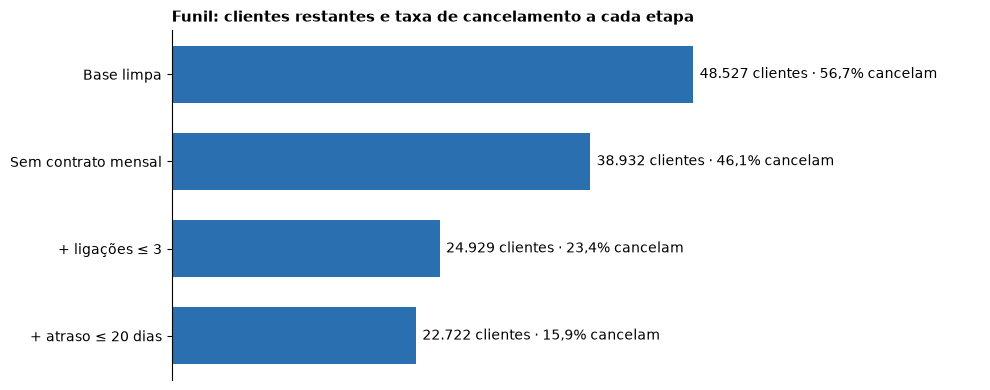

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
y = range(len(funil))[::-1]
ax.barh(list(y), funil['Clientes'], color=AZUL, height=0.65)
for pos, (_, linha) in zip(y, funil.iterrows()):
    ax.text(linha['Clientes'] + 600, pos,
            f"{milhar(linha['Clientes'])} clientes · {pct(linha['Taxa de cancelamento'])} cancelam",
            va='center', fontsize=10)
ax.set_yticks(list(y)); ax.set_yticklabels(funil['Etapa'])
ax.set_xlim(0, funil['Clientes'].max() * 1.55)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.set_title('Funil: clientes restantes e taxa de cancelamento a cada etapa', loc='left')
fig.tight_layout()
fig.savefig('imagens/funil_cancelamento.png', dpi=110, bbox_inches='tight')
plt.show()

### Comparação: corte da aula (≤ 4 ligações) x corte coerente (≤ 3) e etapas extras

Abaixo, o funil com o corte original de 4 ligações e, na sequência, as duas etapas que a aula não tratou (idade e total gasto).

In [29]:
funil_aula = montar_funil([
    ('Sem contrato mensal',   lambda d: d['duracao_contrato'] != 'Monthly'),
    ('+ ligações ≤ 4 (aula)', lambda d: d['ligacoes_callcenter'] <= 4),
    ('+ atraso ≤ 20 dias',    lambda d: d['dias_atraso'] <= 20),
])
display(formatar_funil(funil_aula))

funil_extra = montar_funil(etapas_principais + [
    ('+ idade ≤ 50',          lambda d: d['idade'] <= 50),
    ('+ total gasto > 500',   lambda d: d['total_gasto'] > 500),
])
display(formatar_funil(funil_extra))

,Etapa,Clientes,Taxa de cancelamento
0,Base limpa,48.527,"56,7%"
1,Sem contrato mensal,38.932,"46,1%"
2,+ ligações ≤ 4 (aula),28.305,"26,4%"
3,+ atraso ≤ 20 dias,25.539,"18,4%"


,Etapa,Clientes,Taxa de cancelamento
0,Base limpa,48.527,"56,7%"
1,Sem contrato mensal,38.932,"46,1%"
2,+ ligações ≤ 3,24.929,"23,4%"
3,+ atraso ≤ 20 dias,22.722,"15,9%"
4,+ idade ≤ 50,21.296,"10,3%"
5,+ total gasto > 500,19.833,"3,7%"


Depois das três ações da aula (com corte ≤ 3), restam **22.722 clientes** e a taxa entre eles é **15,9%**. Com o corte da aula (≤ 4), a taxa seria 18,4%.

Isso **não significa** que a empresa passaria de 56,7% para 15,9%: os clientes removidos do funil continuam existindo. O que cada ação realmente muda é visto na próxima seção.

## 6. Cenários: quanto cada ação reduziria o cancelamento

Para estimar o efeito de uma ação, imagina-se que o grupo-alvo passe a cancelar **como o resto da base**. Com **eficácia de 100%**, a taxa do grupo cai até a do resto. Com **eficácia de 50%**, cai só metade do caminho. A taxa geral é recalculada com todos os clientes.

In [30]:
def taxa_geral_com_acao(mascara, eficacia):
    grupo, resto = tabela_limpa[mascara], tabela_limpa[~mascara]
    taxa_grupo, taxa_resto = grupo['cancelou'].mean(), resto['cancelou'].mean()
    nova_taxa_grupo = taxa_grupo - eficacia * (taxa_grupo - taxa_resto)
    return (resto['cancelou'].sum() + nova_taxa_grupo * len(grupo)) / len(tabela_limpa)

m_mensal = tabela_limpa['duracao_contrato'] == 'Monthly'
m_ligacoes = tabela_limpa['ligacoes_callcenter'] > LIMITE_LIGACOES
m_atraso = tabela_limpa['dias_atraso'] > LIMITE_ATRASO

alvos = {
    'Contrato mensal': m_mensal,
    f'Ligações > {LIMITE_LIGACOES}': m_ligacoes,
    f'Atraso > {LIMITE_ATRASO} dias': m_atraso,
    'As três ações juntas': m_mensal | m_ligacoes | m_atraso,
}
linhas = []
for nome, m in alvos.items():
    linhas.append({'Grupo-alvo': nome, '% da base': pct(m.mean()),
                   'Taxa hoje': pct(taxa_geral),
                   'Com eficácia de 50%': pct(taxa_geral_com_acao(m, 0.5)),
                   'Com eficácia de 100%': pct(taxa_geral_com_acao(m, 1.0))})
cenarios = pd.DataFrame(linhas)
display(cenarios)

,Grupo-alvo,% da base,Taxa hoje,Com eficácia de 50%,Com eficácia de 100%
0,Contrato mensal,"19,8%","56,7%","51,4%","46,1%"
1,Ligações > 3,"41,3%","56,7%","44,8%","32,9%"
2,Atraso > 20 dias,"19,3%","56,7%","51,6%","46,4%"
3,As três ações juntas,"53,2%","56,7%","36,3%","15,9%"


Leitura: se as três ações funcionassem 100%, a taxa geral cairia de 56,7% para cerca de 15,9%. Com 50% de eficácia (hipótese mais conservadora), para 36,3%. São estimativas simplificadas: não consideram custo, nem que os grupos se sobrepõem na prática.

## 7. Cuidados com as conclusões

- **Correlação não é causa.** "Quem liga mais cancela mais" pode significar que o mau atendimento causa o cancelamento, ou que quem já está insatisfeito liga mais. Só um **teste A/B** (aplicar a ação em um grupo e comparar com outro) mostra o efeito real.
- **Viabilidade e custo.** Desconto em plano anual, equipe financeira resolvendo atrasos em 10 dias e processo de atendimento em 3 ligações têm custos. Falta comparar o custo com a receita dos clientes que seriam mantidos.
- **Nem tudo é acionável.** A empresa não muda a idade do cliente. Para `idade` e `total_gasto` a ação seria investigar o motivo (preço? produto?).
- **Sexo não deve ser usado para segmentar ações.** A base mostra diferença (mulheres cancelam mais que homens), mas tratar clientes de forma diferente por sexo é eticamente e, dependendo do caso, legalmente problemático. O melhor é investigar a causa por trás da diferença.

**O que sobra depois das ações?** Entre os clientes que ficam no funil, ainda há quem cancele. Vale olhar o que os diferencia:

In [31]:
tabela_filtrada = tabela_limpa[
    (tabela_limpa['duracao_contrato'] != 'Monthly')
    & (tabela_limpa['ligacoes_callcenter'] <= LIMITE_LIGACOES)
    & (tabela_limpa['dias_atraso'] <= LIMITE_ATRASO)
]
print('Clientes no funil final:', milhar(len(tabela_filtrada)), '| taxa:', pct(tabela_filtrada['cancelou'].mean()))

faixa_interacao = pd.cut(tabela_filtrada['meses_ultima_interacao'], bins=[0, 6, 12, 15, 18, 24, 30])
display(tabela_filtrada.groupby(faixa_interacao, observed=True)['cancelou'].agg(['mean', 'size'])
        .rename(columns={'mean': 'taxa', 'size': 'clientes'}).assign(taxa=lambda d: d['taxa'].map(pct)))
display(tabela_filtrada.groupby('sexo')['cancelou'].mean().map(pct).rename('taxa por sexo (apenas para conferência)'))

Clientes no funil final: 22.722 | taxa: 15,9%


,taxa,clientes
meses_ultima_interacao,,
"(0, 6]","11,6%",5690
"(6, 12]","10,8%",5683
"(12, 15]","12,0%",2903
"(15, 18]","25,4%",1668
"(18, 24]","23,6%",3380
"(24, 30]","22,9%",3398


sexo
Female    24,3%
Male      11,1%
Name: taxa por sexo (apenas para conferência), dtype: str

Entre quem sobra, a taxa sobe quando passam **mais de 15 meses sem interação** com a empresa. Isso sugere uma ação de reativação (contato periódico), mais defensável do que segmentar por sexo.

## 8. Árvore de decisão (scikit-learn): conferindo os cortes

Uma **árvore de decisão** faz perguntas do tipo "ligações > 5,5?" e divide os clientes em grupos o mais "puros" possível (só cancelam ou só ficam). Usamos ela aqui como **confirmação**: se ela achar sozinha os mesmos cortes que encontramos olhando os gráficos, os cortes ganham mais confiança.

Decisões do modelo:

- **`sexo` fica de fora**, pelo motivo da seção 7.
- **`train_test_split` com `stratify`**: 80% treina e 20% testa, mantendo a mesma proporção de cancelamentos nos dois.
- **`max_depth=5` e `min_samples_leaf=100`**: limitam o tamanho da árvore para ela ficar legível e não decorar os dados.
- **`random_state=42`**: o resultado é o mesmo toda vez que rodar.

In [32]:
X = pd.get_dummies(tabela_limpa.drop(columns=['cancelou', 'sexo'])).astype(float)
y = tabela_limpa['cancelou']

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

modelo = DecisionTreeClassifier(max_depth=5, min_samples_leaf=100, random_state=42)
modelo.fit(X_treino, y_treino)

acc_treino = accuracy_score(y_treino, modelo.predict(X_treino))
acc_teste = accuracy_score(y_teste, modelo.predict(X_teste))
print(f'Acerto no treino: {pct(acc_treino)} | acerto no teste: {pct(acc_teste)}')
print()
print(classification_report(y_teste, modelo.predict(X_teste), target_names=['Ficou', 'Cancelou'], digits=3))

Acerto no treino: 97,7% | acerto no teste: 97,8%

              precision    recall  f1-score   support

       Ficou      0.952     1.000     0.975      4198
    Cancelou      1.000     0.961     0.980      5508

    accuracy                          0.978      9706
   macro avg      0.976     0.981     0.978      9706
weighted avg      0.979     0.978     0.978      9706



In [33]:
# Quais cortes a árvore escolheu sozinha?
arv = modelo.tree_
cortes_achados = {}
for feature, corte in zip(arv.feature, arv.threshold):
    if feature >= 0:  # -2 indica folha (sem pergunta)
        cortes_achados.setdefault(X.columns[feature], set()).add(round(float(corte), 1))
for variavel, valores in sorted(cortes_achados.items()):
    print(f'{variavel:28s} -> {sorted(valores)}')

dias_atraso                  -> [20.5]
duracao_contrato_Monthly     -> [0.5]
idade                        -> [49.5, 50.5]
ligacoes_callcenter          -> [4.5, 5.5]
total_gasto                  -> [500.0]


ligacoes_callcenter         38,4%
total_gasto                 26,3%
duracao_contrato_Monthly    15,0%
dias_atraso                 11,1%
idade                        9,1%
Name: importância, dtype: str

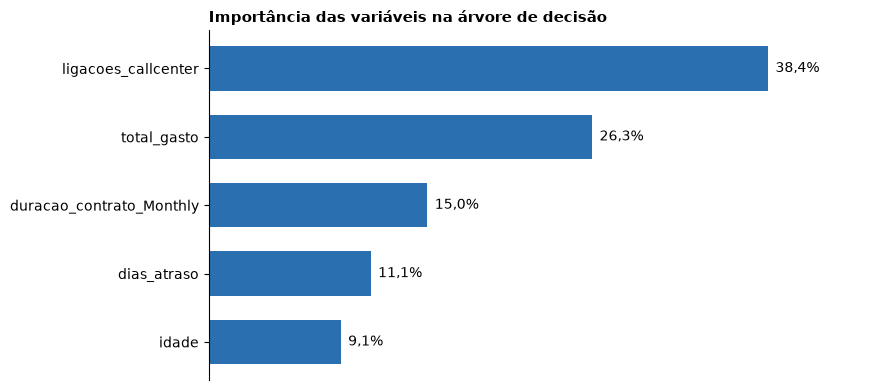

In [34]:
importancias = (pd.Series(modelo.feature_importances_, index=X.columns)
                .sort_values(ascending=False))
importancias = importancias[importancias > 0]
display(importancias.map(pct).rename('importância'))

fig, ax = plt.subplots(figsize=(9, 4))
ordem = importancias.sort_values()
ax.barh(ordem.index, ordem.values, color=AZUL, height=0.65)
for i, v in enumerate(ordem.values):
    ax.text(v + 0.005, i, pct(v), va='center', fontsize=10)
ax.set_xticks([]); ax.spines['bottom'].set_visible(False)
ax.set_xlim(0, ordem.max() * 1.2)
ax.set_title('Importância das variáveis na árvore de decisão', loc='left')
fig.tight_layout()
fig.savefig('imagens/importancia_variaveis.png', dpi=110, bbox_inches='tight')
plt.show()

In [35]:
print(export_text(modelo, feature_names=list(X.columns), max_depth=3))

|--- ligacoes_callcenter <= 4.50
|   |--- total_gasto <= 500.01
|   |   |--- class: 1
|   |--- total_gasto >  500.01
|   |   |--- duracao_contrato_Monthly <= 0.50
|   |   |   |--- dias_atraso <= 20.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- dias_atraso >  20.50
|   |   |   |   |--- class: 1
|   |   |--- duracao_contrato_Monthly >  0.50
|   |   |   |--- class: 1
|--- ligacoes_callcenter >  4.50
|   |--- ligacoes_callcenter <= 5.50
|   |   |--- idade <= 49.50
|   |   |   |--- class: 1
|   |   |--- idade >  49.50
|   |   |   |--- idade <= 50.50
|   |   |   |   |--- class: 0
|   |   |   |--- idade >  50.50
|   |   |   |   |--- class: 1
|   |--- ligacoes_callcenter >  5.50
|   |   |--- class: 1



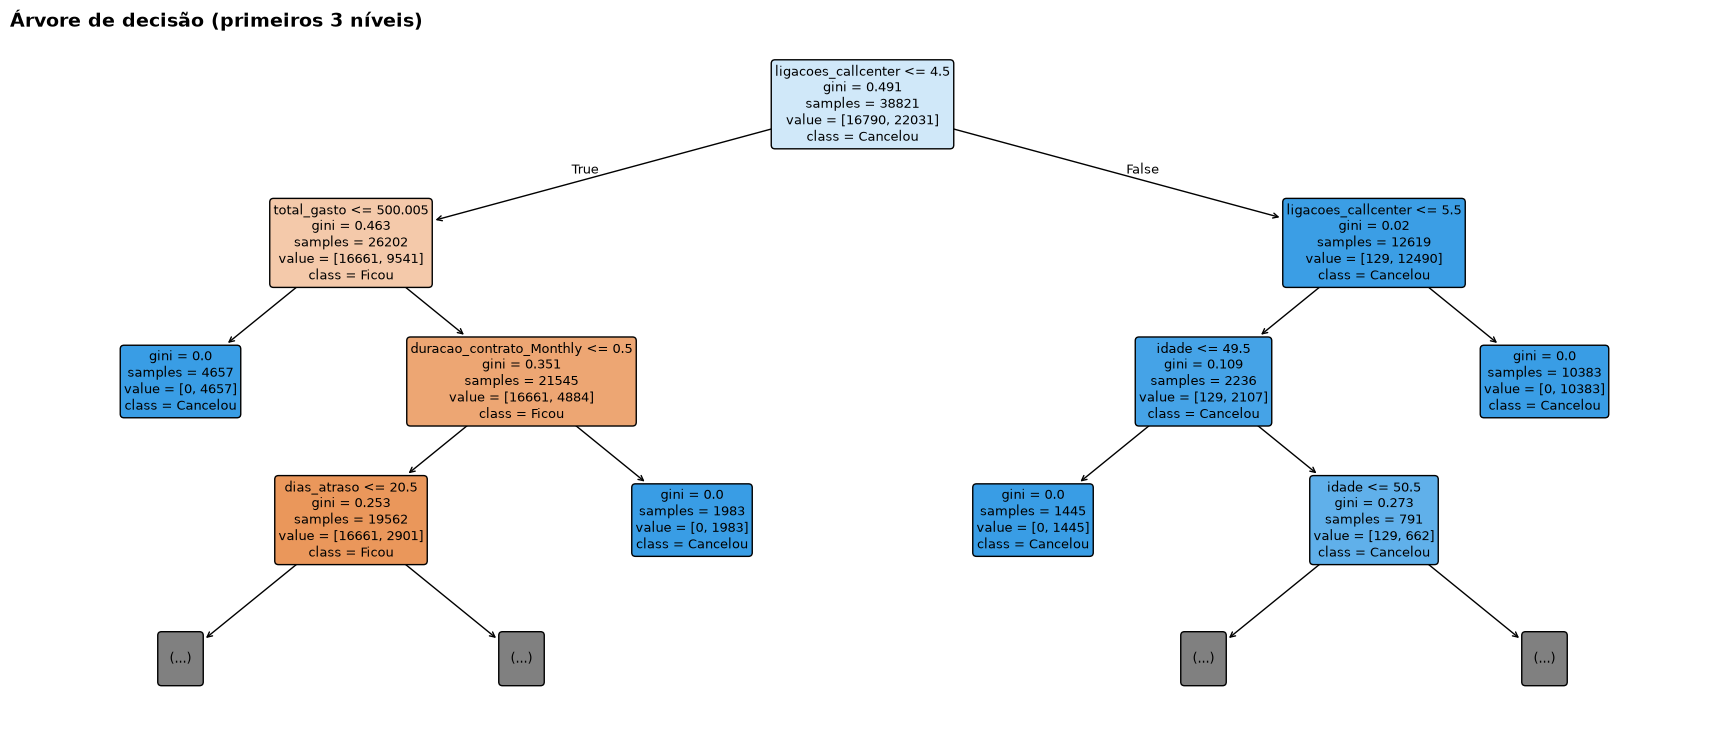

In [36]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(modelo, feature_names=list(X.columns), class_names=['Ficou', 'Cancelou'],
          filled=True, rounded=True, max_depth=3, fontsize=9, proportion=False, ax=ax)
ax.set_title('Árvore de decisão (primeiros 3 níveis)', loc='left', fontsize=14, fontweight='bold')
fig.savefig('imagens/arvore_decisao.png', dpi=100, bbox_inches='tight')
plt.show()

**Como interpretar**

- A árvore acerta **97,8%** dos clientes de teste. **Esse número não deve ser levado como "o modelo é ótimo"**: ele é irrealista porque a base é fictícia e as regras são muito limpas (grupos com 100% de cancelamento). Em dados reais, o acerto seria bem menor.
- O papel da árvore aqui é **confirmar os cortes**: ela encontrou ligações entre 4 e 6, atraso em 20 dias, contrato mensal, total gasto em 500 e idade em 50. São os mesmos pontos de virada da seção 4.
- A importância mostra quais variáveis mais separam quem cancela de quem fica: ligações, total gasto, contrato mensal, atraso e idade. Importância **não é causa**: é só quanto a variável ajudou a dividir os dados.

## 9. Conclusões

**O que os dados mostram**

- A base limpa tem 48.527 clientes e 56,7% cancelaram.
- Cinco fatores concentram o cancelamento: **contrato mensal, 6 ou mais ligações ao call center, atraso acima de 20 dias, idade acima de 50 e total gasto até 500**. Nesses grupos a taxa é de 100%.
- A árvore de decisão confirmou os mesmos cortes de forma independente.

**Ações sugeridas (da aula, com ajustes)**

1. Oferecer desconto em planos trimestrais e anuais para clientes mensais.
2. Criar um processo para resolver o problema do cliente em **até 3 ligações** (corte corrigido de 4 para 3).
3. Política de resolver atrasos em até 10 dias, com a equipe financeira.
4. Investigar por que clientes com mais de 50 anos e com gasto baixo cancelam (não tratado na aula).
5. Contato de reativação para quem passa muito tempo sem interação.

**Impacto estimado:** com as três ações da aula e eficácia de 100%, a taxa geral iria de 56,7% para cerca de 15,9%; com 50%, para 36,3%.

**Limitações**

- Base fictícia: padrões e acerto irreais.
- Correlação não é causa: validar com teste A/B antes de investir.
- Sem custos: não dá para dizer ainda quais ações valem a pena financeiramente.
- Cenários simplificados: tratam os grupos como independentes.